### Cell 1 – Install libraries

In [1]:
!pip install -q kagglehub

### Cell 2 – Download dataset and create RFM table

In [2]:
import glob
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("carrie1/ecommerce-data")
file = glob.glob(path + "/*.csv")[0]

df = pd.read_csv(
    file,
    encoding="ISO-8859-1",
    usecols=[0, 3, 4, 5, 6],
    header=0,
    names=["InvoiceNo", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"],
)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df = df.dropna(subset=["CustomerID"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["Amount"] = df["Quantity"] * df["UnitPrice"]

snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda d: (snapshot_date - d.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Amount", "sum"),
)

print(rfm.shape)
rfm.head()

Using Colab cache for faster access to the 'ecommerce-data' dataset.
(4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


### Cell 3 – Scale the data

In [3]:
import numpy as np
from sklearn.preprocessing import StandardScaler

scaled = StandardScaler().fit_transform(np.log1p(rfm))

### Cell 4 – Elbow and silhouette

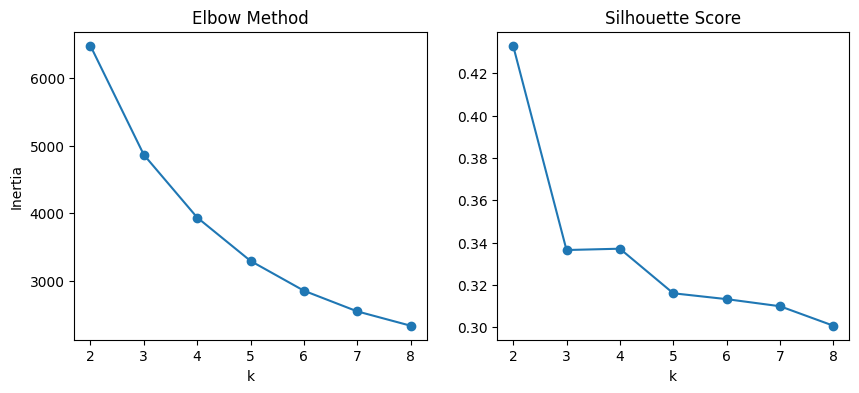

In [4]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 9)
inertia = []
silhouette = []

for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(scaled)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(scaled, model.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertia, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inertia")
ax[1].plot(ks, silhouette, marker="o")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("k")
plt.show()

### Cell 5 – K-Means

In [5]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
rfm["KMeans"] = kmeans.fit_predict(scaled)

print(rfm["KMeans"].value_counts().sort_index())

KMeans
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64


### Cell 6 – DBSCAN

In [6]:
from sklearn.cluster import DBSCAN

rfm["DBSCAN"] = DBSCAN(eps=0.5, min_samples=10).fit_predict(scaled)

print(rfm["DBSCAN"].value_counts().sort_index())

DBSCAN
-1      79
 0    2780
 1    1479
Name: count, dtype: int64


### Cell 7 – PCA and t-SNE

Variance explained: 0.939


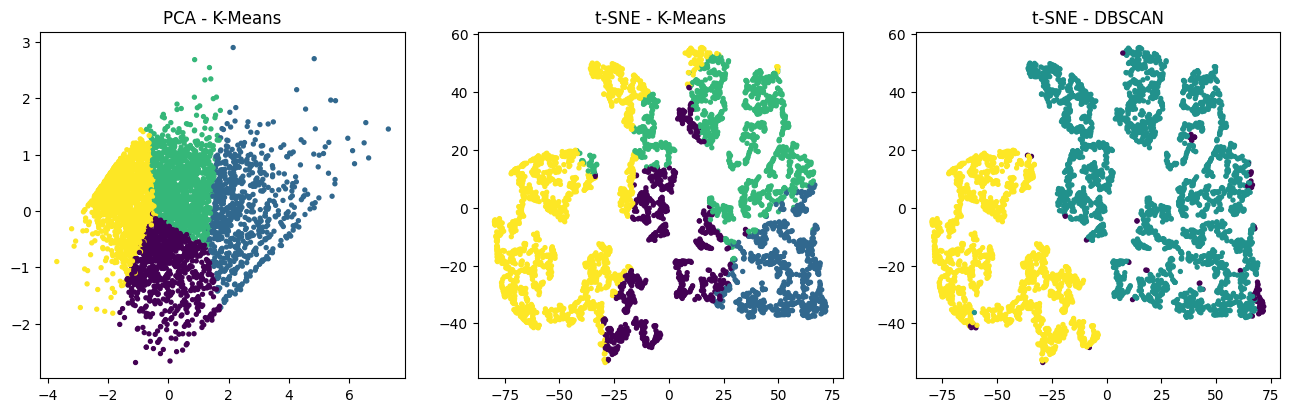

In [7]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled)
print("Variance explained:", round(pca.explained_variance_ratio_.sum(), 3))

tsne_data = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(scaled)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(pca_data[:, 0], pca_data[:, 1], c=rfm["KMeans"], cmap="viridis", s=8)
ax[0].set_title("PCA - K-Means")
ax[1].scatter(tsne_data[:, 0], tsne_data[:, 1], c=rfm["KMeans"], cmap="viridis", s=8)
ax[1].set_title("t-SNE - K-Means")
ax[2].scatter(tsne_data[:, 0], tsne_data[:, 1], c=rfm["DBSCAN"], cmap="viridis", s=8)
ax[2].set_title("t-SNE - DBSCAN")
plt.show()

### Cell 8 – Customer personas

In [8]:
summary = rfm.groupby("KMeans").agg(
    Customers=("Recency", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
).round(1)
print(summary)

personas = {
    (True, True): ("Champions", "Reward with loyalty points and early access to new products."),
    (True, False): ("Promising Customers", "Send welcome offers and cross-sell to increase purchase frequency."),
    (False, True): ("At-Risk Big Spenders", "Run a win-back campaign with a personal discount."),
    (False, False): ("Lost Customers", "Send a low-cost re-engagement email."),
}

for cluster, row in summary.iterrows():
    recent = bool(row["Recency"] < rfm["Recency"].median())
    big_spender = bool(row["Monetary"] > rfm["Monetary"].median())
    name, action = personas[(recent, big_spender)]
    print(f"\nCluster {cluster}: {name} ({int(row['Customers'])} customers)\n  Action: {action}")

        Customers  Recency  Frequency  Monetary
KMeans                                         
0             837     18.1        2.1     551.8
1             716     12.1       13.7    8074.3
2            1173     71.1        4.1    1802.8
3            1612    182.5        1.3     343.5

Cluster 0: Promising Customers (837 customers)
  Action: Send welcome offers and cross-sell to increase purchase frequency.

Cluster 1: Champions (716 customers)
  Action: Reward with loyalty points and early access to new products.

Cluster 2: At-Risk Big Spenders (1173 customers)
  Action: Run a win-back campaign with a personal discount.

Cluster 3: Lost Customers (1612 customers)
  Action: Send a low-cost re-engagement email.
